Ali Hisham AlJamed 2240005868 7MA1 / MA01

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Balls.png'   

Task 1 – Erosion, Dilation, Opening, Closing 

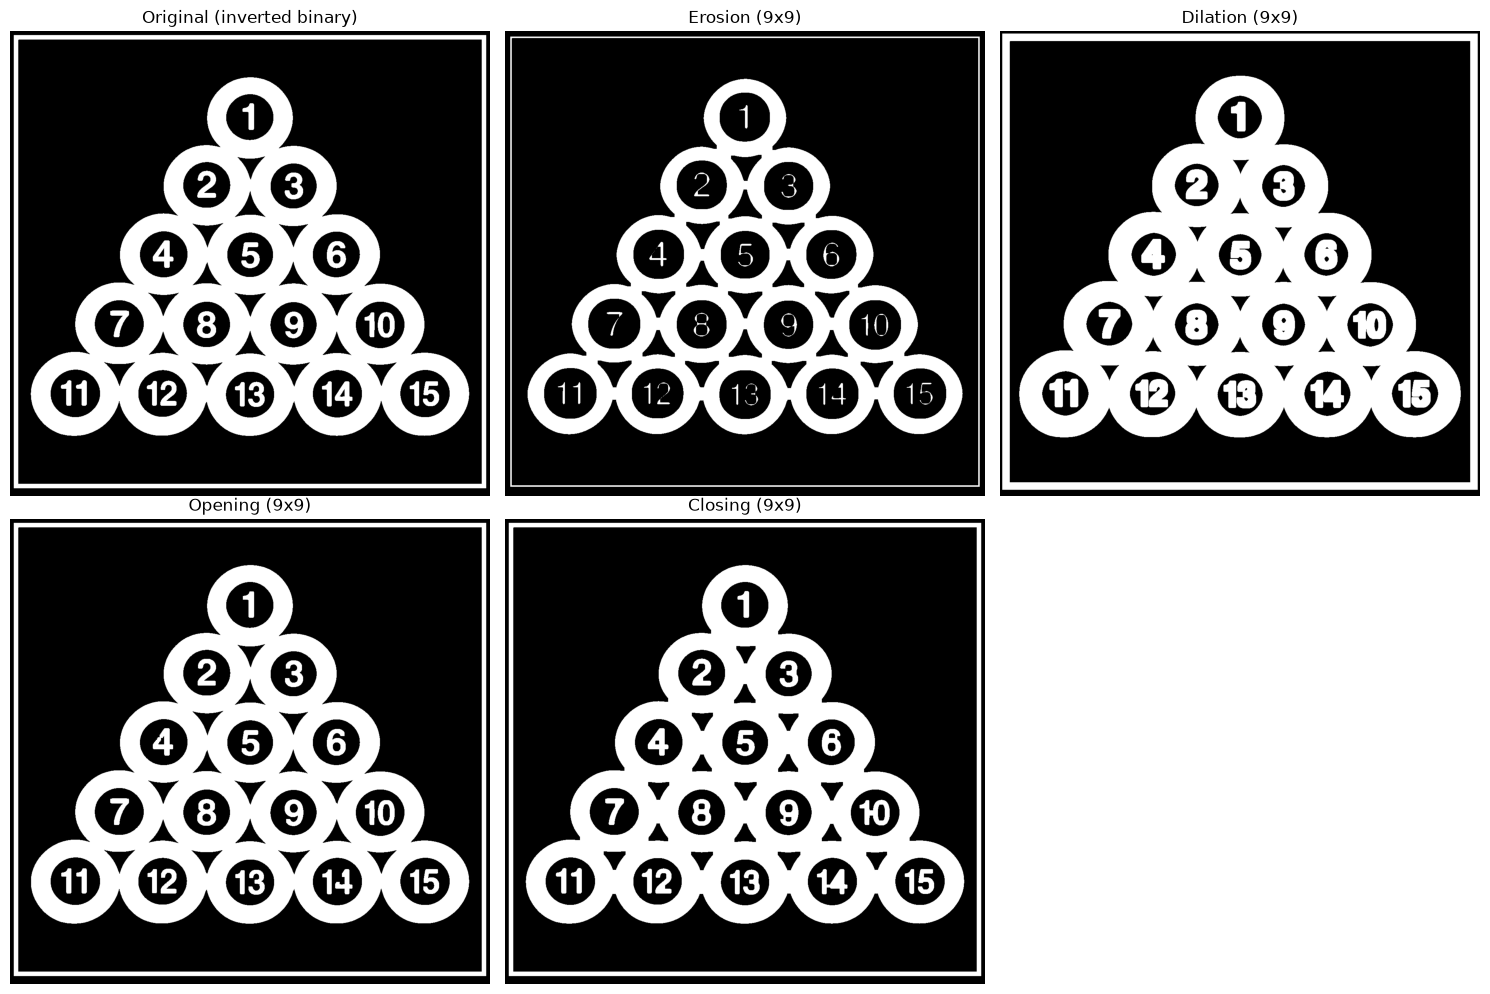

In [2]:
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 2. 9x9 square kernel
kernel = np.ones((9, 9), np.uint8)

# 3. The four operations
eroded   = cv2.erode(binary, kernel, iterations=1)
dilated  = cv2.dilate(binary, kernel, iterations=1)
opening  = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel)   # dilate(erode(A))
closing  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)   # erode(dilate(A))

# 4. Display
titles = ['Original (inverted binary)', 'Erosion (9x9)', 'Dilation (9x9)', 'Opening (9x9)', 'Closing (9x9)']
images = [binary, eroded, dilated, opening, closing]

plt.figure(figsize=(15, 10))
for i, (t, im) in enumerate(zip(titles, images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(im, 'gray'), plt.title(t), plt.axis('off')
plt.tight_layout()
plt.show()

Task 2 Structuring element shapes and kernel sizes

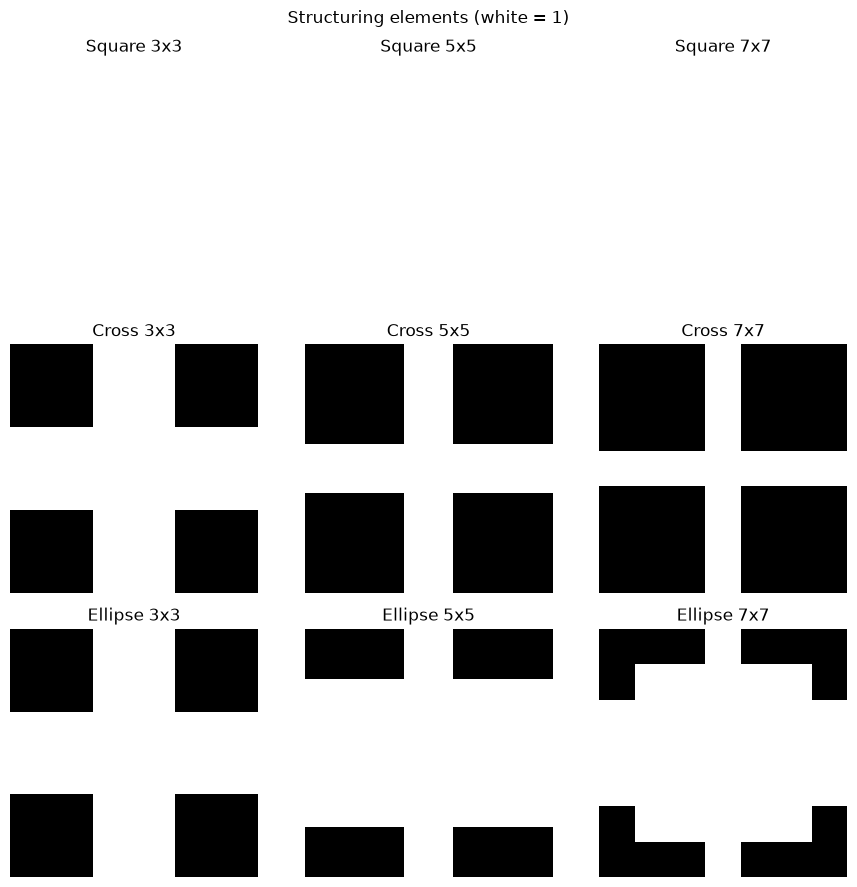

Square 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Square 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

Cross 7x7:
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]

Ellipse 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

Ellipse 7x7:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]



In [3]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes  = [3, 5, 7]

# Visualize the structuring elements themselves
plt.figure(figsize=(9, 9))
k = 1
for name, shp in shapes.items():
    for s in sizes:
        plt.subplot(3, 3, k); k += 1
        plt.imshow(cv2.getStructuringElement(shp, (s, s)), 'gray', vmin=0, vmax=1)
        plt.title(f'{name} {s}x{s}'); plt.axis('off')
plt.suptitle('Structuring elements (white = 1)')
plt.tight_layout(); plt.show()

# Print them too
for name, shp in shapes.items():
    for s in (5, 7):
        print(f'{name} {s}x{s}:\n{cv2.getStructuringElement(shp, (s, s))}\n')

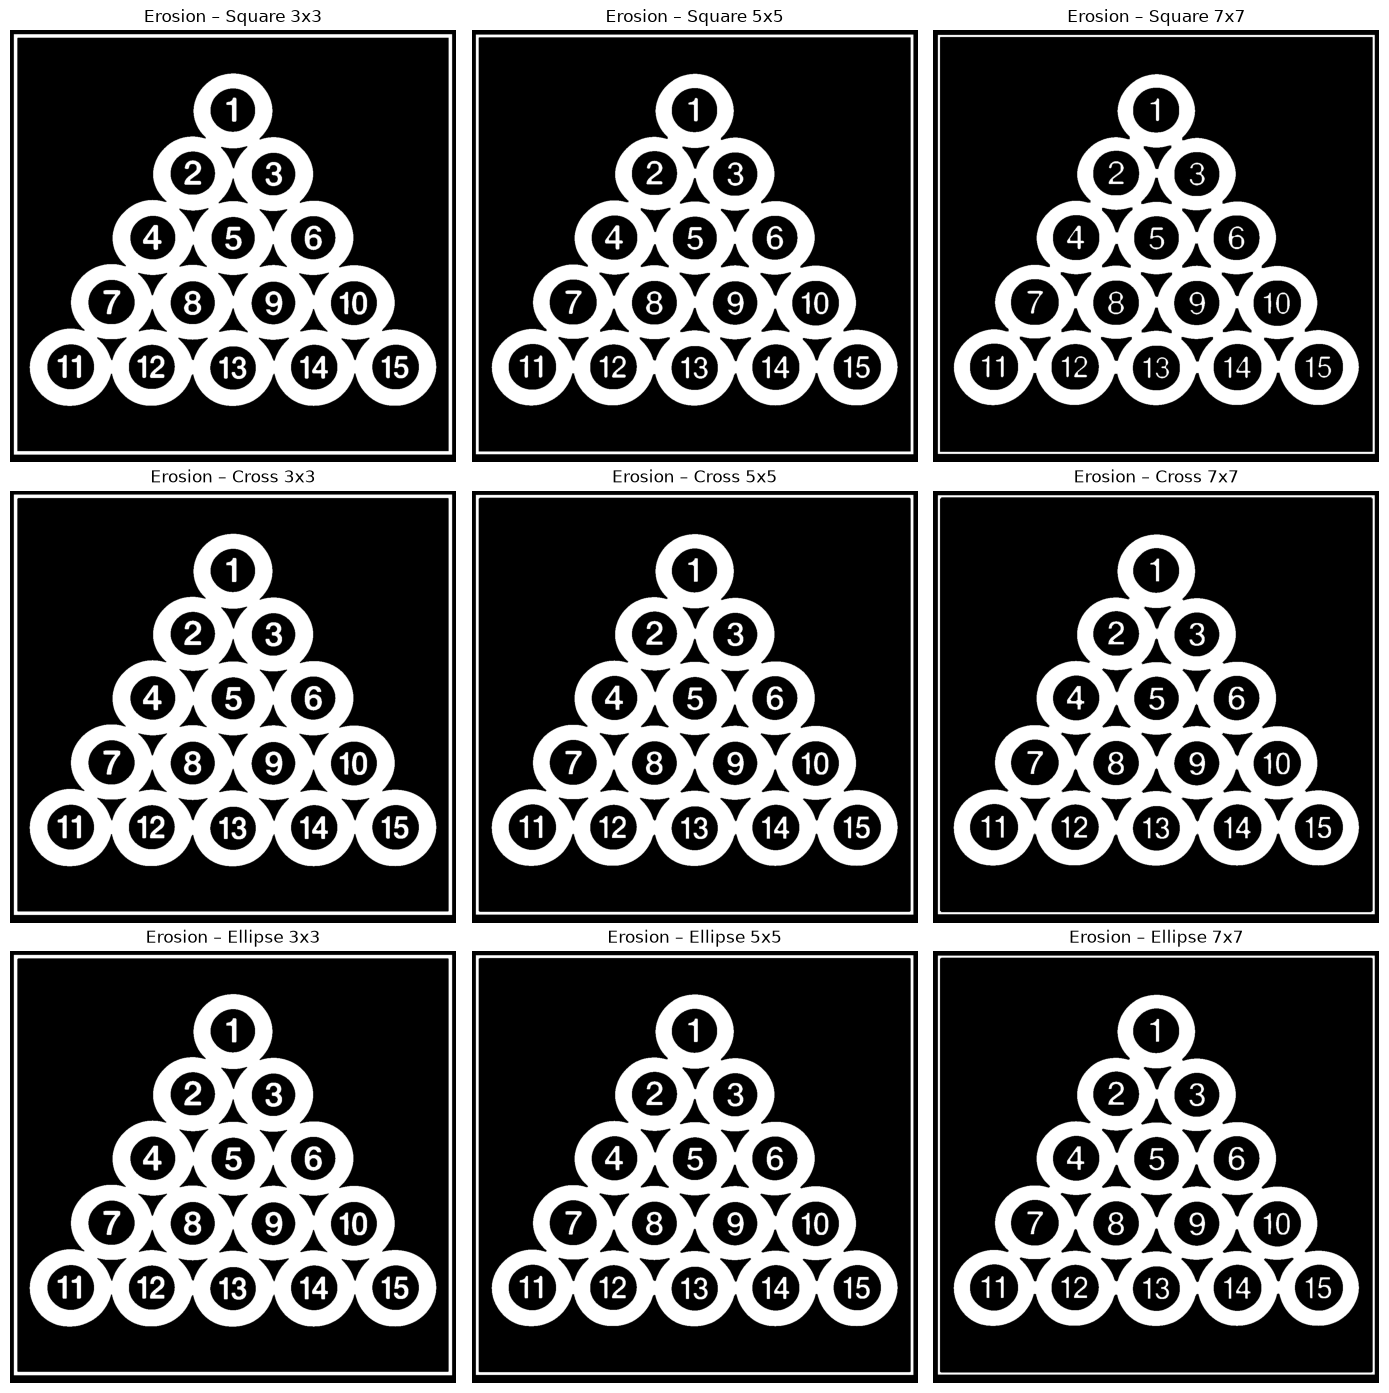

In [4]:
def grid(op_name, op_func):
    """Rows = shape, columns = kernel size."""
    fig, axes = plt.subplots(3, 3, figsize=(14, 14))
    for r, (name, shp) in enumerate(shapes.items()):
        for c, s in enumerate(sizes):
            se = cv2.getStructuringElement(shp, (s, s))
            axes[r, c].imshow(op_func(binary, se), 'gray')
            axes[r, c].set_title(f'{op_name} – {name} {s}x{s}')
            axes[r, c].axis('off')
    plt.tight_layout(); plt.show()

grid('Erosion',  lambda im, se: cv2.erode(im, se))

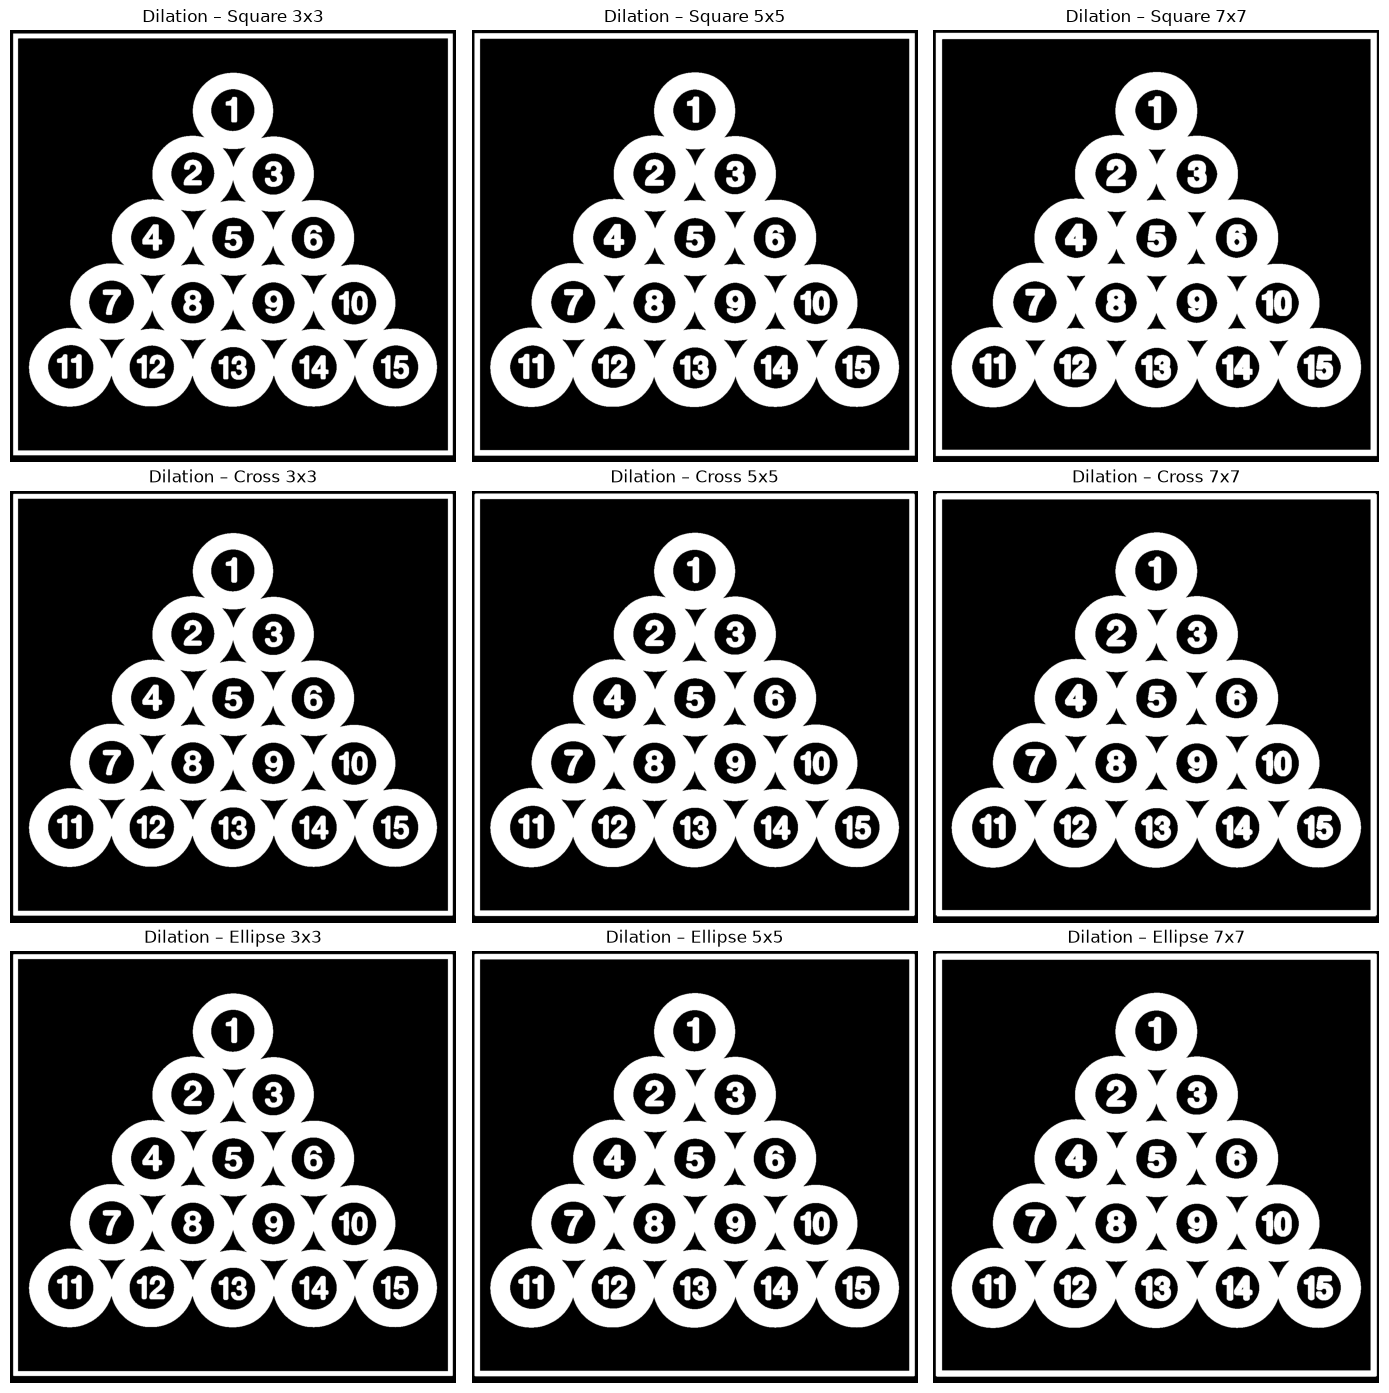

In [5]:
grid('Dilation', lambda im, se: cv2.dilate(im, se))

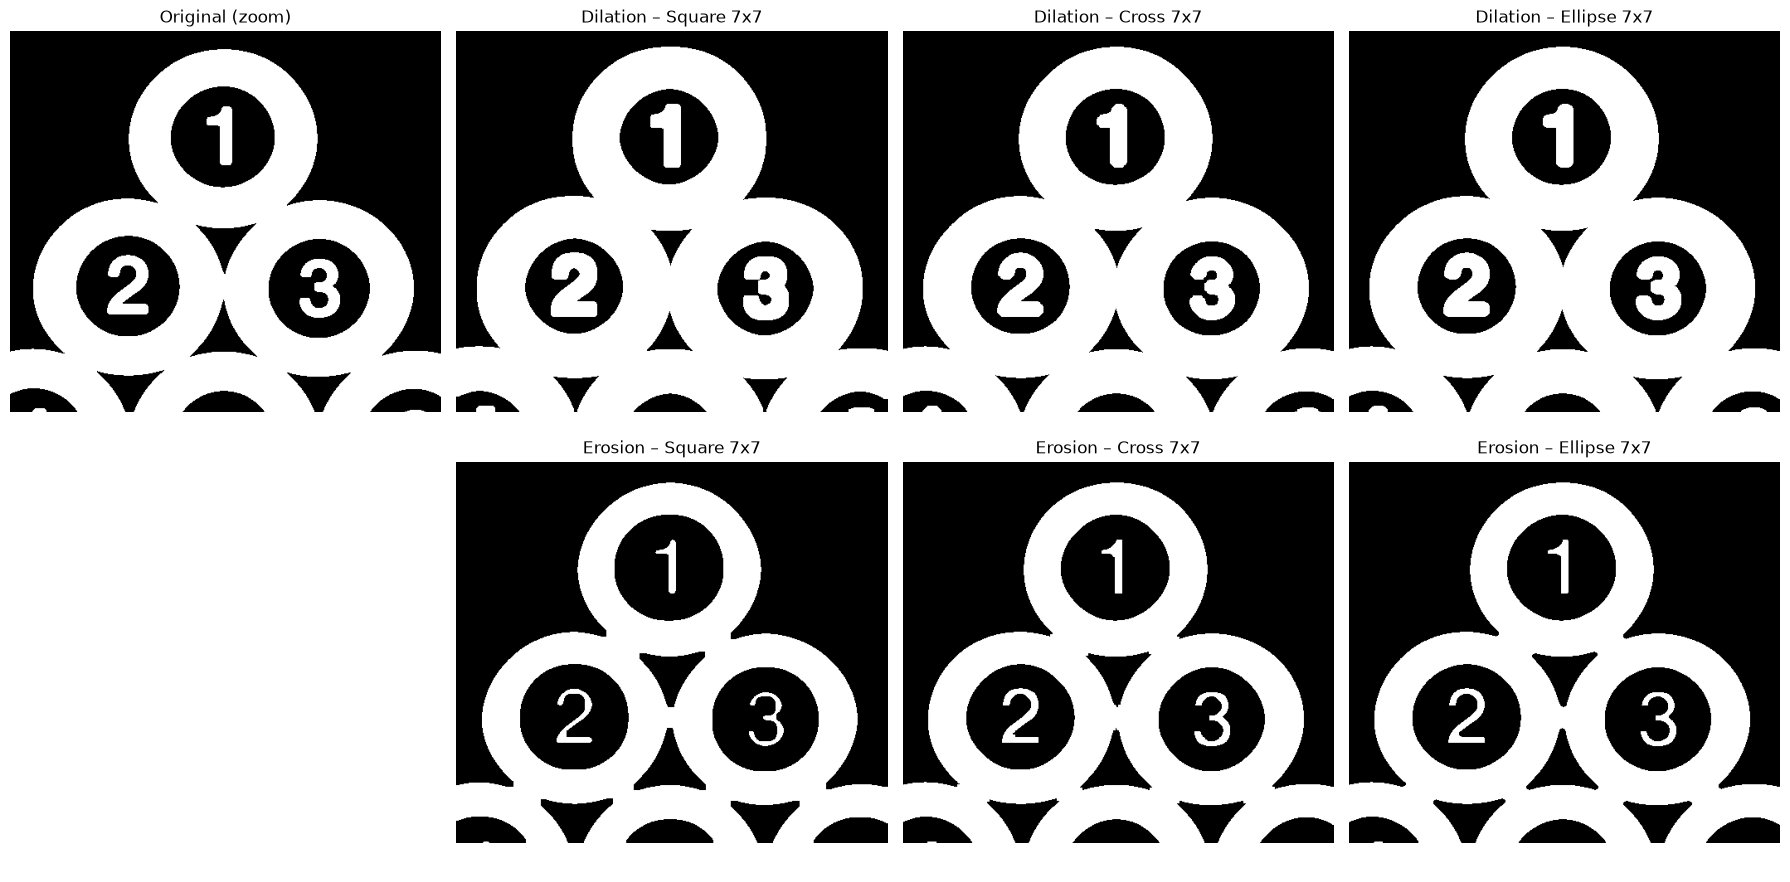

In [6]:
# Zoom into the top of the rack (balls 1,2,3)
y0, y1, x0, x1 = 100, 560, 380, 900
roi = binary[y0:y1, x0:x1]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, im, t in zip(axes.ravel()[:1], [roi], ['Original (zoom)']):
    ax.imshow(im, 'gray'); ax.set_title(t); ax.axis('off')
axes.ravel()[1].axis('off'); axes.ravel()[2].axis('off'); axes.ravel()[3].axis('off')

# Same size (7x7), different shapes: erosion (row 2) vs dilation shown in first row
for i, (name, shp) in enumerate(shapes.items()):
    se = cv2.getStructuringElement(shp, (7, 7))
    axes[0, i + 1].imshow(cv2.dilate(roi, se), 'gray'); axes[0, i + 1].set_title(f'Dilation – {name} 7x7'); axes[0, i + 1].axis('off')
    axes[1, i + 1].imshow(cv2.erode(roi,  se), 'gray'); axes[1, i + 1].set_title(f'Erosion – {name} 7x7');  axes[1, i + 1].axis('off')
axes[1, 0].axis('off')
plt.tight_layout(); plt.show()

In [7]:
# Quantify: how much white (foreground) is left / gained, in % of the original
orig = np.count_nonzero(binary)
print(f"{'Shape':8s} {'Size':5s} {'Erosion area %':>15s} {'Dilation area %':>16s}")
for name, shp in shapes.items():
    for s in sizes:
        se = cv2.getStructuringElement(shp, (s, s))
        e = np.count_nonzero(cv2.erode(binary, se))  / orig * 100
        d = np.count_nonzero(cv2.dilate(binary, se)) / orig * 100
        print(f'{name:8s} {s}x{s}  {e:15.1f} {d:16.1f}')

Shape    Size   Erosion area %  Dilation area %
Square   3x3             93.2            106.7
Square   5x5             86.4            113.3
Square   7x7             79.6            119.8
Cross    3x3             94.6            105.4
Cross    5x5             89.1            110.8
Cross    7x7             83.7            116.1
Ellipse  3x3             94.6            105.4
Ellipse  5x5             88.1            111.8
Ellipse  7x7             82.6            117.1
